# Topological Anomaly Detection in ECG Signals
*Applied AI/ML · Signal Processing · TDA* — Hassan Farid

## Objective
Investigate whether topological features can provide useful representations for ECG anomaly detection, and compare them with conventional signal features.

## Methods (as set out on the project page) and where each is done here
| Planned method | In this notebook |
|---|---|
| ECG preprocessing | Light preprocessing in section 2: zero-padding trimmed, Savitzky-Golay smoothing. Band-pass filtering and baseline correction were already applied by the dataset authors. |
| Beat segmentation | Not repeated. The dataset provides pre-segmented single beats (187 samples each). |
| Time-delay embedding | Section 4 |
| Persistent homology | Section 4 (alpha complex, H0, H1, H2) |
| Persistence images | Section 4 (H1) |
| Persistence landscapes | Section 4 (H1) |
| Betti curves and persistence entropy | Section 4 (Betti curves from H1; entropy for H0, H1, H2) |
| Isolation Forest, One-Class SVM | Section 5 (trained on normal beats only) |
| Comparison with conventional signal features | Sections 3 and 5: conventional / topological / combined, plus an ablation of each topological representation |

## Data source
MIT-BIH Arrhythmia Database (PhysioNet), the intended real-world dataset. This notebook uses the pre-segmented Kaggle version, **ECG Heartbeat Categorization Dataset** (`mitbih_train.csv`): one beat per row, 187 samples, last column is the class (0 = normal, 1-4 = abnormal types). Check the dataset page for its exact preparation details and cite the original database (Moody & Mark, 2001; Goldberger et al., 2000).

**Setup:** click *Add Input* and add that dataset. Turn **Internet on** in the notebook settings so the first cell can install `gudhi`.

> **Status note.** Earlier prototype work for this project used synthetic signals and must not be read as a real-world finding. If this notebook falls back to the synthetic practice file (it prints which file it used), its results are not findings either.

In [1]:
!pip install gudhi -q

In [2]:
import glob, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, gudhi
from scipy.stats import skew, kurtosis
from scipy.signal import savgol_filter
from gudhi.representations import PersistenceImage, Landscape, BettiCurve
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
warnings.filterwarnings('ignore')
REQUIRE_REAL = True      # True: stop if the real MIT-BIH file is missing. False: allow the synthetic practice file (results are NOT findings)
SEED = 42; rng = np.random.default_rng(SEED)
N_TRAIN, N_VAL, N_TEST_NORM, N_TEST_ANOM = 1500, 300, 800, 200   # test set is 20% anomalies
EMB_DIM, TAU = 3, 8                                              # time-delay embedding

## 1. Load data

In [3]:
allcsv = glob.glob('/kaggle/input/**/*.csv', recursive=True)
print('CSV files visible to this notebook:', allcsv)
low = lambda f: f.lower()
real = [f for f in allcsv if 'mitbih_train' in low(f)] or [f for f in allcsv if 'mitbih' in low(f) and 'test' not in low(f)]
if not real:                                               # last resort: any 188-column headerless CSV that is not the PTB set
    for f in allcsv:
        if 'ptb' in low(f) or 'synthetic' in low(f): continue
        try:
            if pd.read_csv(f, header=None, nrows=2).shape[1] == 188: real = [f]; print('Using', f, '(188 columns: assumed MIT-BIH beats + label)'); break
        except Exception: pass
if real:
    raw = pd.read_csv(real[0], header=None)
    X_all = raw.iloc[:, :-1].values.astype(float); y_all = (raw.iloc[:, -1].values != 0).astype(int)
    SOURCE = 'MIT-BIH (Kaggle pre-segmented beats)'; print('Real MIT-BIH file:', real[0])
else:                                                       # practice file from the data pack
    if REQUIRE_REAL:
        raise FileNotFoundError("mitbih_train.csv not found. Click 'Add Input', search 'ECG Heartbeat Categorization Dataset' and add it, then rerun. (Set REQUIRE_REAL = False in the first code cell to practise on the synthetic file.)")
    syn = glob.glob('/kaggle/input/**/ecg_beats_synthetic.csv', recursive=True) + glob.glob('ecg_beats_synthetic.csv')
    raw = pd.read_csv(syn[0]); X_all = raw.filter(regex='^s[0-9]+$').values; y_all = raw.label.values
    SOURCE = 'SYNTHETIC practice data (not a finding)'; print('SYNTHETIC practice file:', syn[0])
print(X_all.shape, 'anomaly share:', y_all.mean().round(3))

CSV files visible to this notebook: ['/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv', '/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv', '/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_abnormal.csv', '/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_normal.csv']
Real MIT-BIH file: /kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv
(87554, 187) anomaly share: 0.172


In [4]:
norm_idx = rng.permutation(np.where(y_all==0)[0]); anom_idx = rng.permutation(np.where(y_all==1)[0])
tr  = norm_idx[:N_TRAIN]; val = norm_idx[N_TRAIN:N_TRAIN+N_VAL]
te  = np.concatenate([norm_idx[N_TRAIN+N_VAL:N_TRAIN+N_VAL+N_TEST_NORM], anom_idx[:N_TEST_ANOM]])
RAW = {'tr': X_all[tr], 'val': X_all[val], 'te': X_all[te]}; yte = y_all[te]
print({k: len(v) for k, v in RAW.items()}, '| test anomaly share:', yte.mean())

{'tr': 1500, 'val': 300, 'te': 1000} | test anomaly share: 0.2


## 2. Preprocessing
Beats are zero-padded to a fixed length. We trim the padding (so it does not distort the embedding) and smooth lightly. Segmentation and filtering were done by the dataset authors.

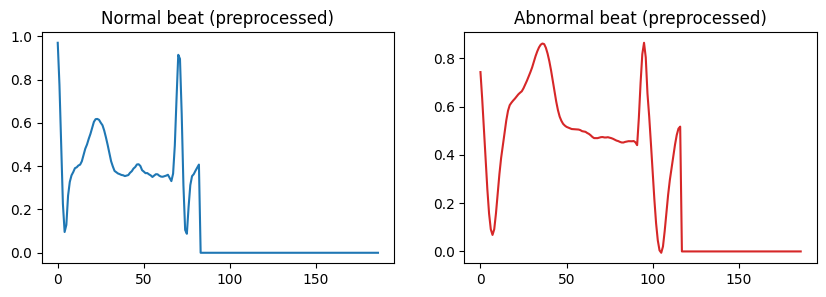

In [5]:
def preprocess(x):
    nz = np.nonzero(x)[0]; end = nz[-1] + 1 if len(nz) else len(x)
    beat = x[:end]
    if len(beat) >= 9: beat = savgol_filter(beat, 7, 3)
    full = np.r_[beat, np.zeros(len(x) - len(beat))]          # fixed-length version for conventional features
    return beat, full
PRE = {k: [preprocess(x) for x in X] for k, X in RAW.items()}
fig, ax = plt.subplots(1, 2, figsize=(10,3))
ax[0].plot(preprocess(X_all[norm_idx[0]])[1]); ax[0].set_title('Normal beat (preprocessed)')
ax[1].plot(preprocess(X_all[anom_idx[0]])[1], color='C3'); ax[1].set_title('Abnormal beat (preprocessed)'); plt.show()

## 3. Conventional signal features
Summary statistics, beat length and low-frequency spectrum.

In [6]:
def conv_feats(beat, full):
    mag = np.abs(np.fft.rfft(full))[:16]
    base = [beat.mean(), beat.std(), skew(beat), kurtosis(beat), beat.max(), beat.min(),
            np.argmax(beat)/len(full), np.argmin(beat)/len(full), (beat**2).mean(),
            ((beat[:-1]*beat[1:]) < 0).sum(), len(beat)/len(full)]
    return np.array(base + list(mag))
CONV = {k: np.vstack([conv_feats(b, f) for b, f in v]) for k, v in PRE.items()}
print('conventional features:', CONV['tr'].shape[1])

conventional features: 27


## 4. Topological features
Time-delay embedding turns each beat into a 3D point cloud. Persistent homology (alpha complex) gives H0, H1 and H2 diagrams, which we represent four ways: persistence statistics with entropy, Betti curves, persistence landscapes and persistence images.

In [7]:
def embed(beat, dim=EMB_DIM, tau=TAU):
    z = (beat - beat.mean()) / (beat.std() + 1e-8)
    n = len(z) - (dim-1)*tau
    return np.stack([z[i*tau : i*tau + n] for i in range(dim)], axis=1)

def diagrams(beat):
    if len(beat) < 30: beat = np.r_[beat, np.zeros(30 - len(beat))]
    st = gudhi.AlphaComplex(points=embed(beat)).create_simplex_tree(); st.persistence()
    out = {}
    for d in (0, 1, 2):
        iv = st.persistence_intervals_in_dimension(d)
        iv = iv[np.isfinite(iv[:,1])] if len(iv) else np.zeros((0,2))
        out[d] = np.sqrt(iv)                      # alpha filtration stores squared radii
    return out

t = time.time()
DG = {k: [diagrams(b) for b, _ in v] for k, v in PRE.items()}
print('persistent homology computed in', round(time.time()-t), 's for', sum(len(v) for v in DG.values()), 'beats')

persistent homology computed in 16 s for 2800 beats


In [8]:
def summarise(iv):
    if len(iv) == 0: return [0, 0, 0, 0, 0]
    l = iv[:,1] - iv[:,0]; p = l / l.sum() if l.sum() > 0 else l
    return [len(l), l.sum(), l.max(), l.mean(), -(p[p>0]*np.log(p[p>0])).sum()]   # last = persistence entropy

def stats_entropy(D):
    f = []
    for d in (0, 1, 2): f += summarise(D[d])
    h1 = np.sort(D[1][:,1] - D[1][:,0])[::-1] if len(D[1]) else np.array([])
    return f + [h1[0] if len(h1) > 0 else 0, h1[1] if len(h1) > 1 else 0]

fix = lambda iv: iv if len(iv) else np.array([[0., 0.]])      # vectorisers need at least one point
H1 = {k: [fix(D[1]) for D in v] for k, v in DG.items()}
PI = PersistenceImage(resolution=[6,6], bandwidth=0.05, weight=lambda x: x[1]).fit(H1['tr'])
LS = Landscape(num_landscapes=2, resolution=20).fit(H1['tr'])
BC = BettiCurve(resolution=20).fit(H1['tr'])
TOPO = {name: {k: (np.array([stats_entropy(D) for D in DG[k]]) if name=='persistence stats + entropy' else vec.transform(H1[k])) for k in DG}
        for name, vec in [('persistence stats + entropy', None), ('Betti curve (H1)', BC), ('landscape (H1)', LS), ('persistence image (H1)', PI)]}
print({n: v['tr'].shape[1] for n, v in TOPO.items()})

{'persistence stats + entropy': 17, 'Betti curve (H1)': 20, 'landscape (H1)': 40, 'persistence image (H1)': 36}


## 4b. Visualising the topology: randomly selected examples
Random normal and abnormal beats are drawn from the test set. For each one the figure shows every step of the pipeline: preprocessed beat, time-delay point cloud, persistence diagram and barcode (H0, H1, H2), Betti curves, persistence landscape and persistence image. Class-level pictures follow.

- This file has **no patient IDs**, so beats are chosen at random. If a file does have patient IDs (the practice file does), the code first picks random patients, then one random beat from each.
- Set `SHOW_SEED = None` for a different random selection every run, and change `N_EACH` for more examples. Figures are saved to `figures/` for your portfolio.

In [9]:
import os
SAVE_FIGS, SHOW_SEED, N_EACH = True, 7, 3      # SHOW_SEED = None -> different random beats every run
if SAVE_FIGS: os.makedirs('figures', exist_ok=True)
PID = raw['patient_id'].values[te] if 'patient_id' in raw.columns else None

def pick_examples(n_each=N_EACH, seed=SHOW_SEED):
    r = np.random.default_rng(seed); chosen = []
    for label in (0, 1):
        idx = np.where(yte == label)[0]
        if PID is not None:                                   # random patients first, then one random beat each
            pats = r.permutation(np.unique(PID[idx]))[:n_each]
            sel = [r.choice(idx[PID[idx] == p]) for p in pats]
        else:
            sel = list(r.choice(idx, n_each, replace=False))
        chosen += [(int(i), label) for i in sel]
    return chosen
PICKS = pick_examples()
print('Random patients, one beat each.' if PID is not None else 'No patient IDs in this file: showing random beats.', '| (test index, label):', PICKS)

No patient IDs in this file: showing random beats. | (test index, label): [(754, 0), (499, 0), (547, 0), (965, 1), (845, 1), (953, 1)]


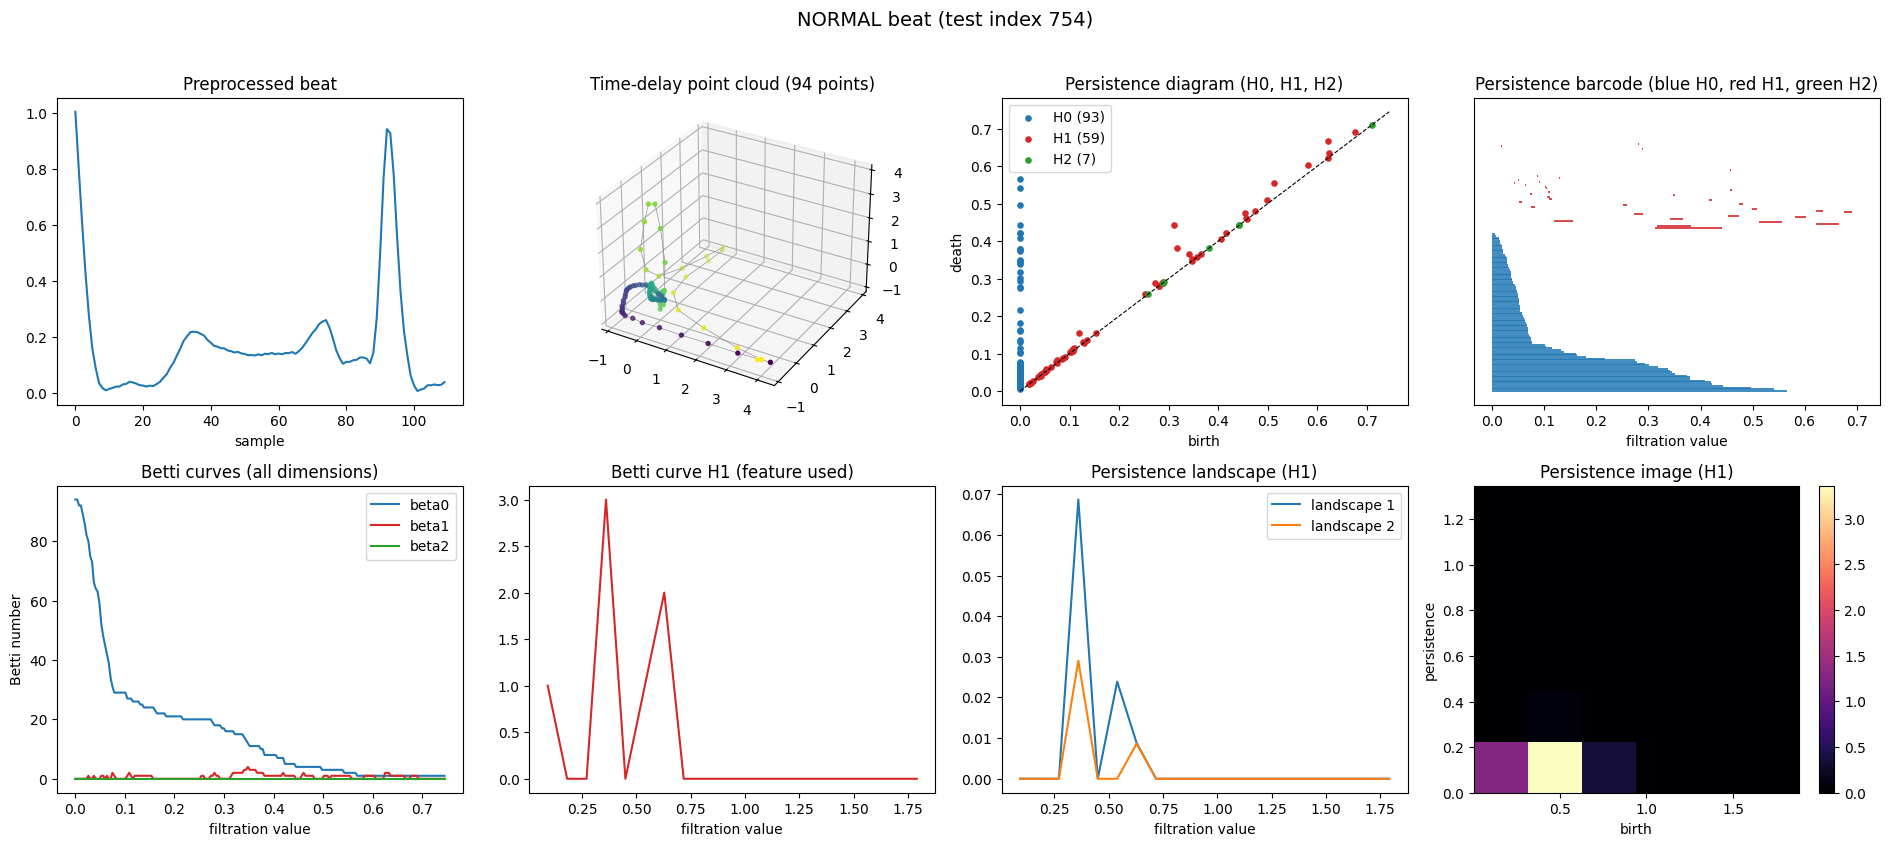

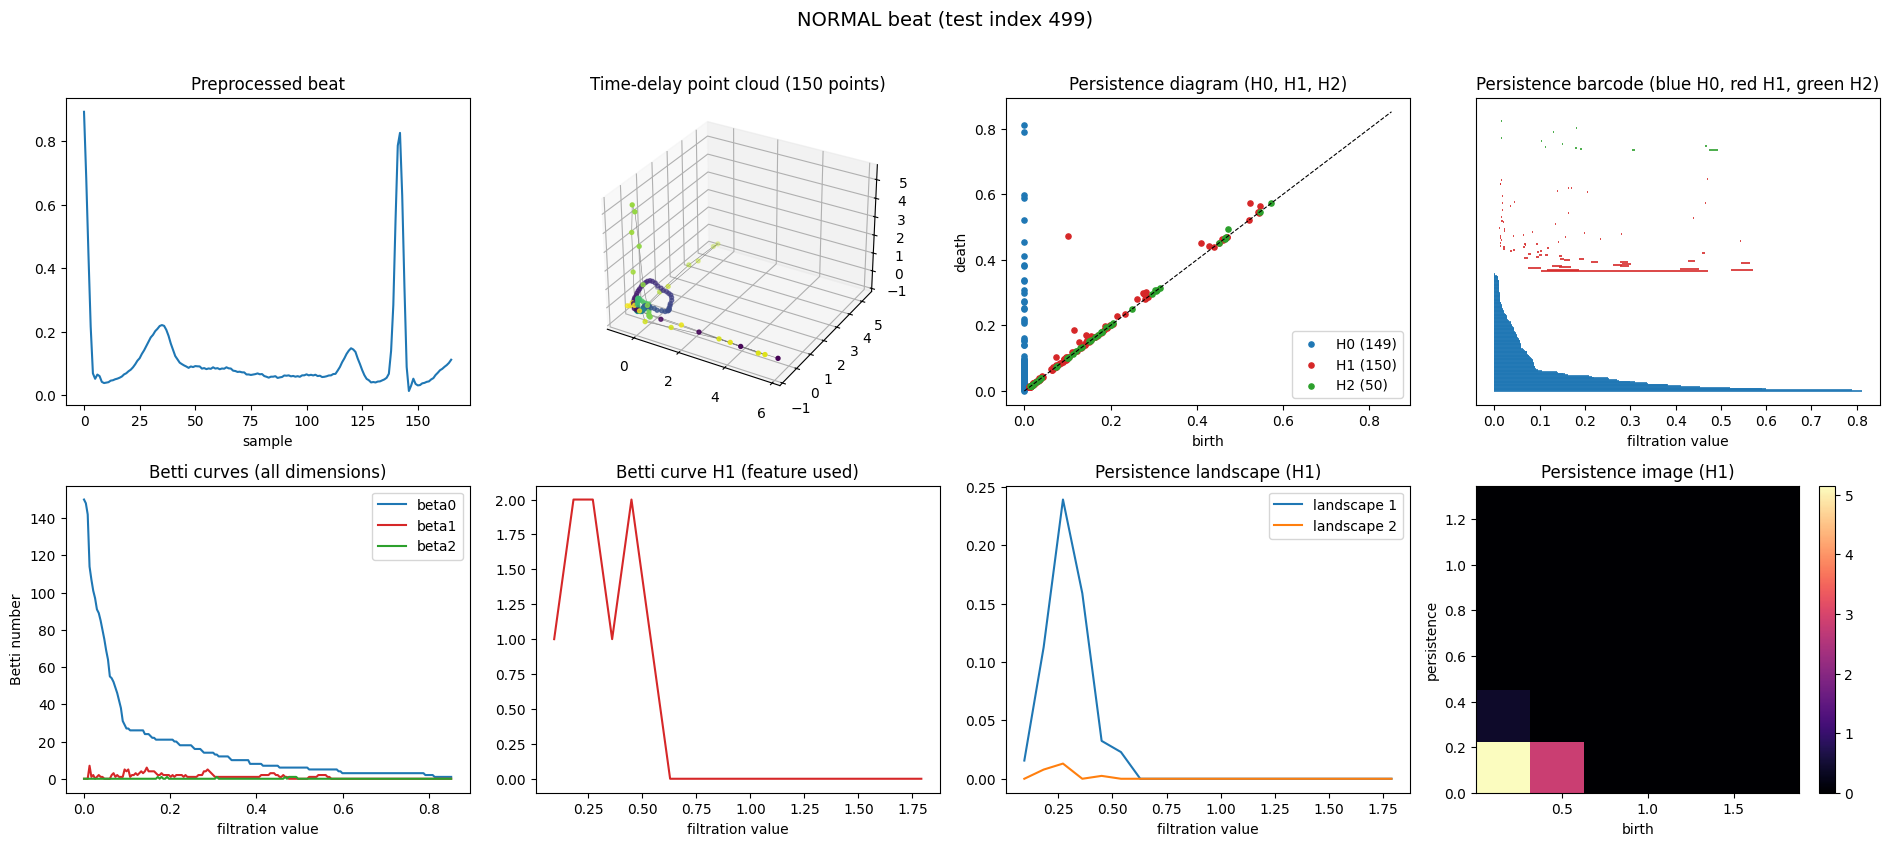

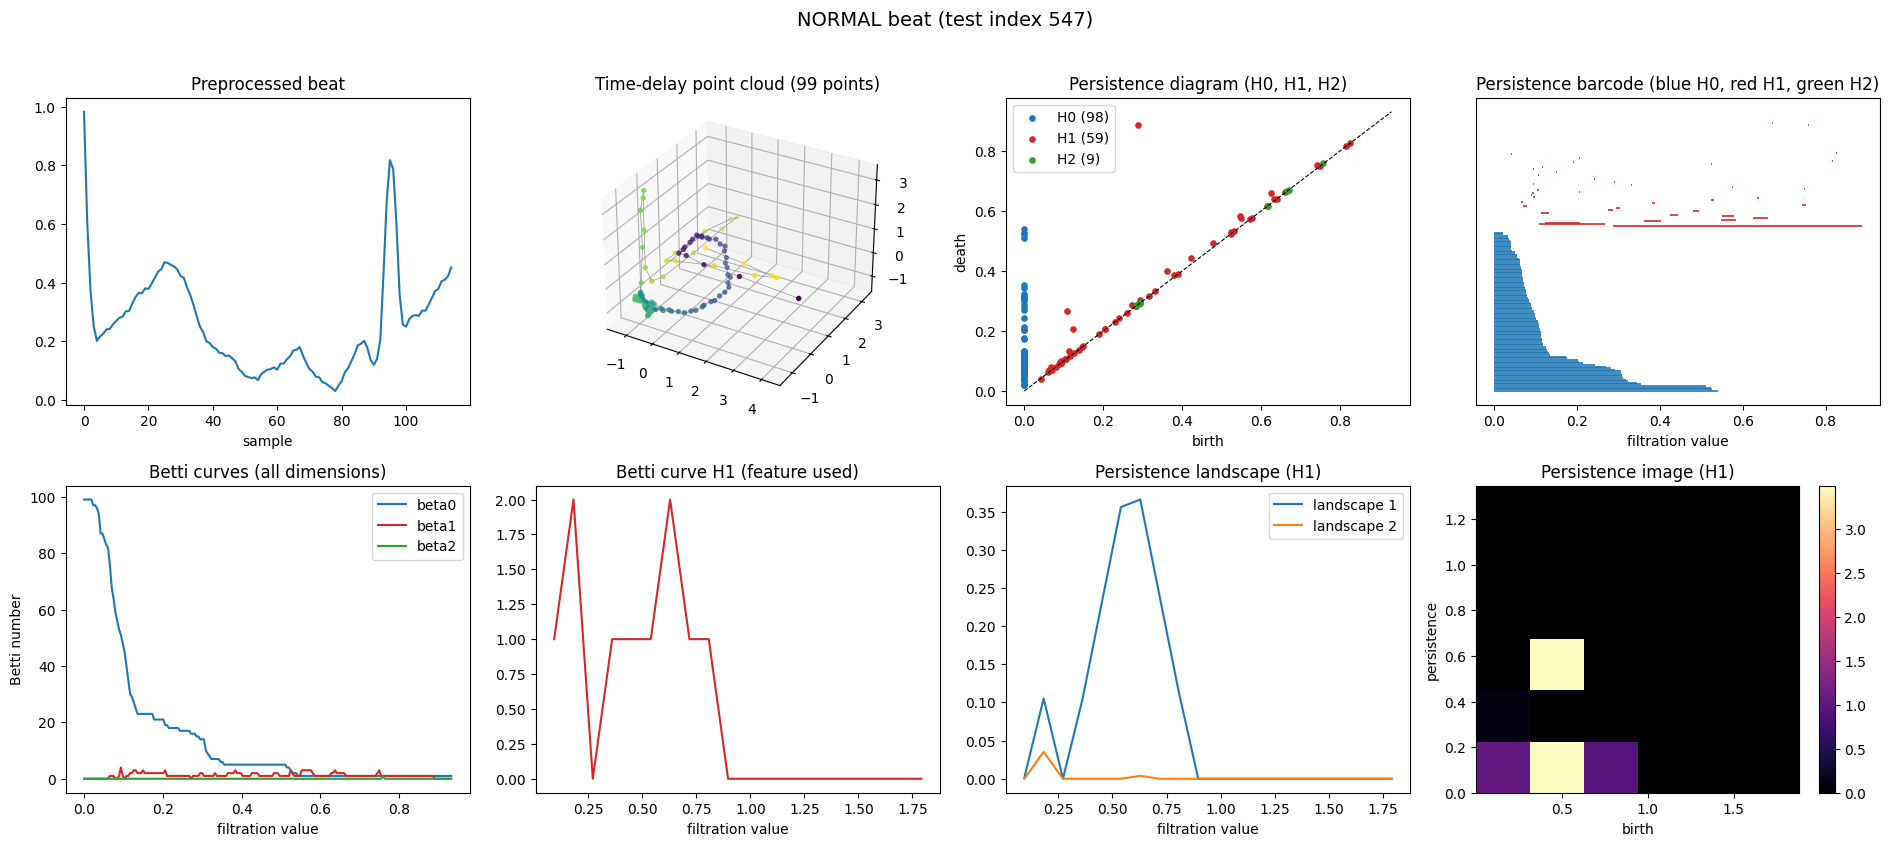

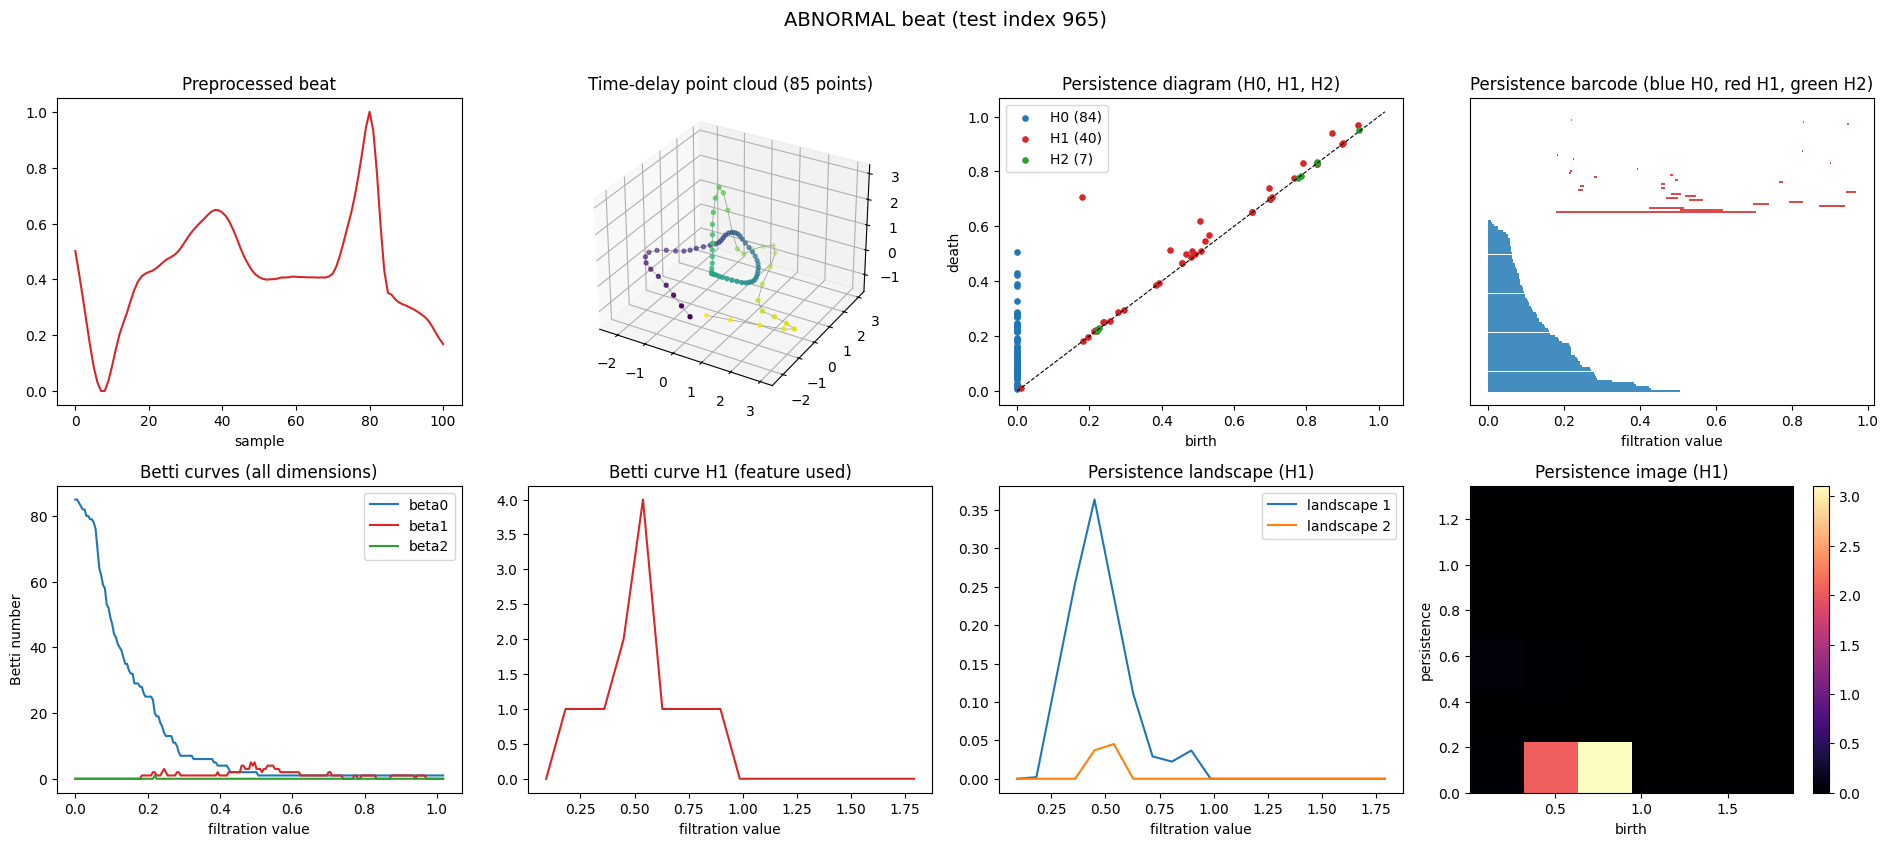

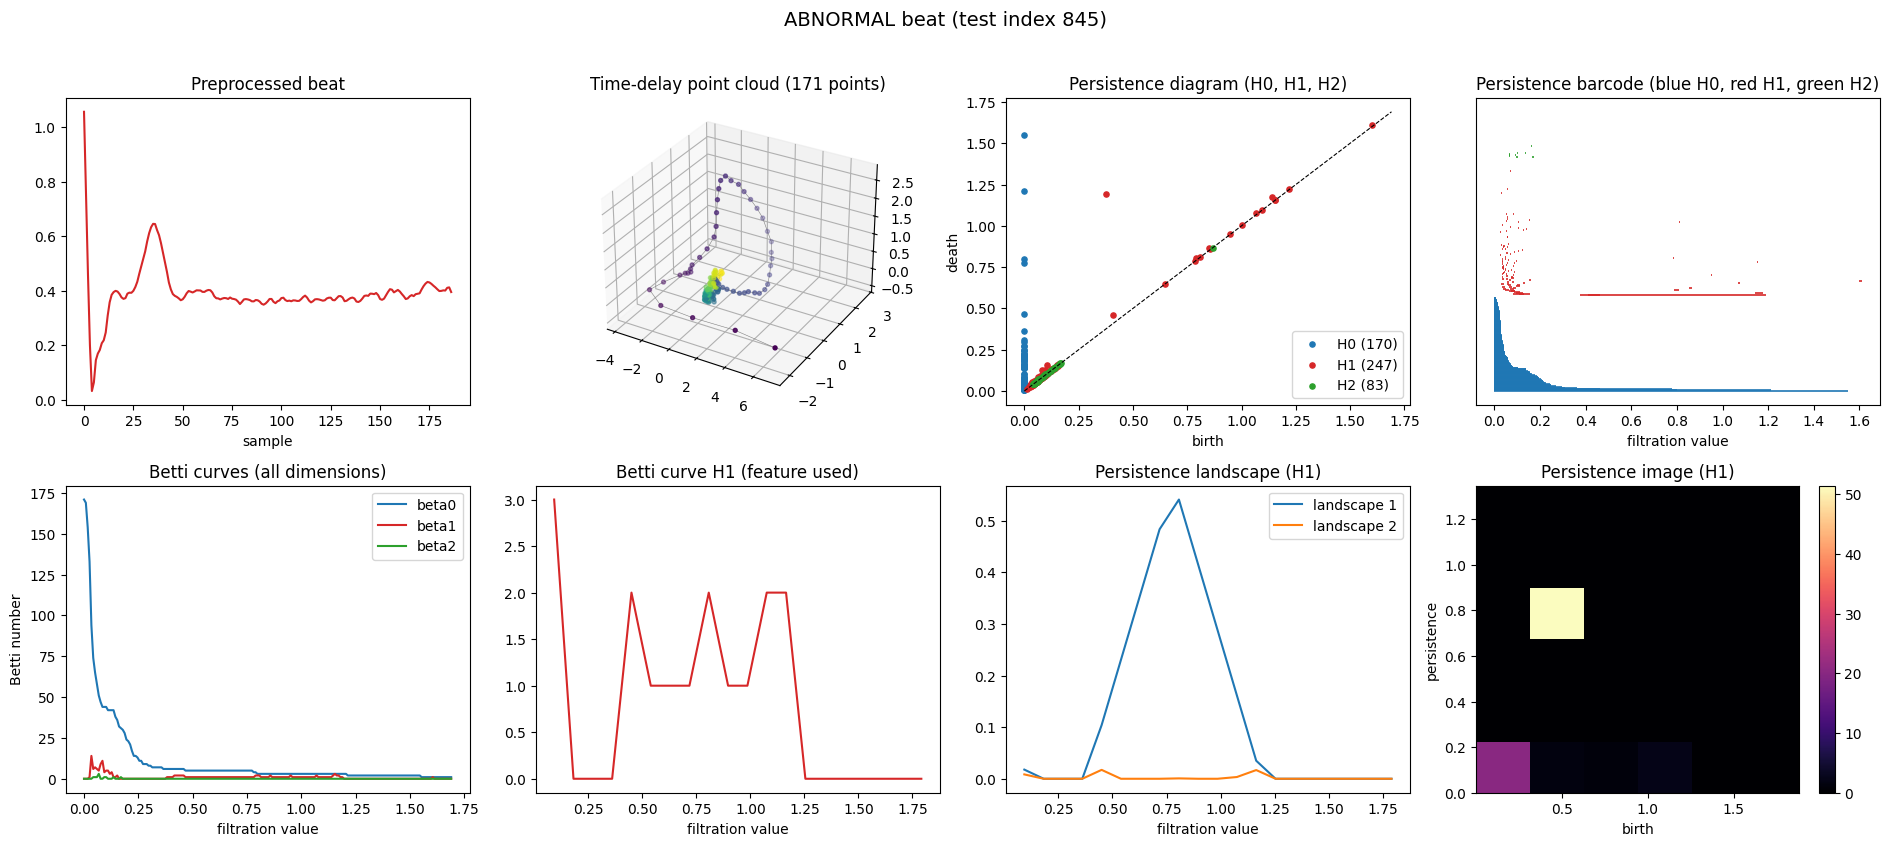

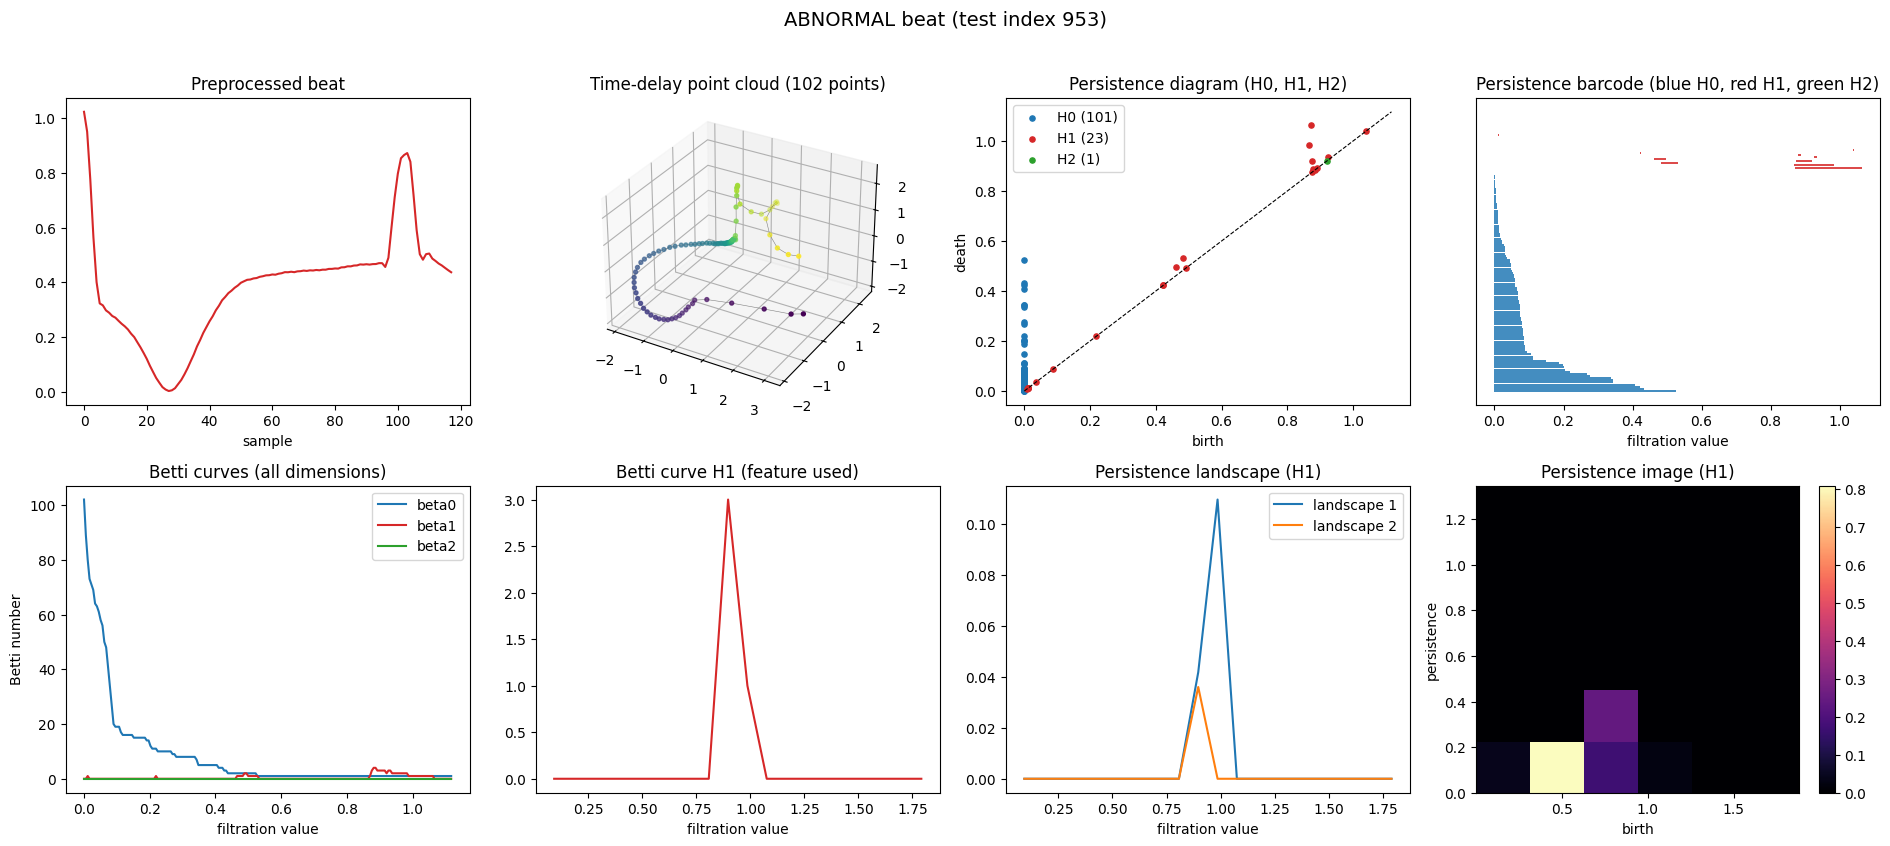

In [10]:
COL = {0: 'C0', 1: 'C3', 2: 'C2'}

def betti_curve(iv, grid, infinite=0):
    return np.array([infinite + (np.sum((iv[:,0] <= t) & (iv[:,1] > t)) if len(iv) else 0) for t in grid])

def show_beat(i, label):
    beat, full = PRE['te'][i]; D = DG['te'][i]; pts = embed(beat)
    tag = 'ABNORMAL' if label else 'NORMAL'
    fig = plt.figure(figsize=(19, 8.5)); fig.suptitle(f'{tag} beat (test index {i})' + (f', patient {PID[i]}' if PID is not None else ''), fontsize=14, y=0.99)
    ax = fig.add_subplot(2, 4, 1); ax.plot(beat, color='C3' if label else 'C0'); ax.set_title('Preprocessed beat'); ax.set_xlabel('sample')
    ax = fig.add_subplot(2, 4, 2, projection='3d')
    ax.plot(pts[:,0], pts[:,1], pts[:,2], lw=.4, color='gray'); ax.scatter(pts[:,0], pts[:,1], pts[:,2], c=np.arange(len(pts)), cmap='viridis', s=8)
    ax.set_title(f'Time-delay point cloud ({len(pts)} points)')
    ax = fig.add_subplot(2, 4, 3); top = max([D[d].max() for d in D if len(D[d])] + [0.1]) * 1.05
    for d in (0, 1, 2):
        if len(D[d]): ax.scatter(D[d][:,0], D[d][:,1], s=14, c=COL[d], label=f'H{d} ({len(D[d])})')
    ax.plot([0, top], [0, top], 'k--', lw=.8); ax.set_xlabel('birth'); ax.set_ylabel('death'); ax.legend(); ax.set_title('Persistence diagram (H0, H1, H2)')
    ax = fig.add_subplot(2, 4, 4); y = 0
    for d in (0, 1, 2):
        iv = D[d][np.argsort(-(D[d][:,1] - D[d][:,0]))] if len(D[d]) else D[d]
        for b_, e_ in iv: ax.hlines(y, b_, e_, color=COL[d], lw=1.2); y += 1
        y += 3
    ax.set_xlabel('filtration value'); ax.set_yticks([]); ax.set_title('Persistence barcode (blue H0, red H1, green H2)')
    ax = fig.add_subplot(2, 4, 5); g = np.linspace(0, top, 200)
    for d in (0, 1, 2): ax.plot(g, betti_curve(D[d], g, infinite=1 if d == 0 else 0), color=COL[d], label=f'beta{d}')
    ax.set_xlabel('filtration value'); ax.set_ylabel('Betti number'); ax.legend(); ax.set_title('Betti curves (all dimensions)')
    ax = fig.add_subplot(2, 4, 6); ax.plot(BC.grid_, BC.transform([fix(D[1])])[0], color='C3'); ax.set_title('Betti curve H1 (feature used)'); ax.set_xlabel('filtration value')
    ax = fig.add_subplot(2, 4, 7); Ls = LS.transform([fix(D[1])])[0].reshape(2, -1)
    for k in range(2): ax.plot(LS.grid_, Ls[k], label=f'landscape {k+1}')
    ax.legend(); ax.set_title('Persistence landscape (H1)'); ax.set_xlabel('filtration value')
    ax = fig.add_subplot(2, 4, 8); img = PI.transform([fix(D[1])])[0].reshape(6, 6)
    im = ax.imshow(np.flip(img, 0), extent=PI.im_range_fixed_, aspect='auto', cmap='magma'); plt.colorbar(im, ax=ax)
    ax.set_xlabel('birth'); ax.set_ylabel('persistence'); ax.set_title('Persistence image (H1)')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    if SAVE_FIGS: plt.savefig(f'figures/beat_{tag.lower()}_{i}.png', dpi=130, bbox_inches='tight')
    plt.show()

for i, label in PICKS: show_beat(i, label)

### Class-level and example pictures (examples are the first random normal and abnormal beats above)

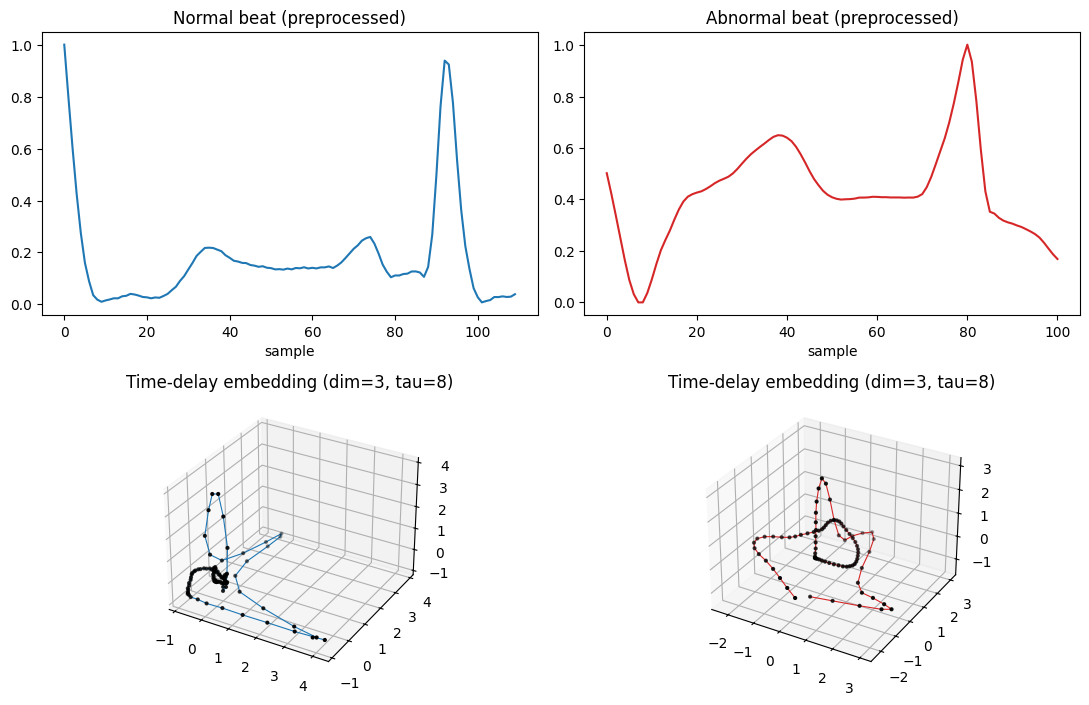

In [11]:
te_norm, te_anom = np.where(yte==0)[0], np.where(yte==1)[0]
EX = {'Normal': next(i for i, l in PICKS if l == 0), 'Abnormal': next(i for i, l in PICKS if l == 1)}; EXCOL = {'Normal': 'tab:blue', 'Abnormal': 'tab:red'}
DCOL = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green'}; DNAME = {0: 'H0', 1: 'H1', 2: 'H2'}

# (a) the beat and its time-delay embedding (3D point cloud)
fig = plt.figure(figsize=(11, 7))
for j, (name, i) in enumerate(EX.items()):
    beat = PRE['te'][i][0]
    ax = fig.add_subplot(2, 2, 1 + j); ax.plot(beat, color=EXCOL[name]); ax.set_title(f'{name} beat (preprocessed)'); ax.set_xlabel('sample')
    P = embed(beat); ax = fig.add_subplot(2, 2, 3 + j, projection='3d')
    ax.plot(P[:,0], P[:,1], P[:,2], lw=.8, color=EXCOL[name]); ax.scatter(P[:,0], P[:,1], P[:,2], s=4, color='k')
    ax.set_title(f'Time-delay embedding (dim={EMB_DIM}, tau={TAU})')
plt.tight_layout(); plt.show()

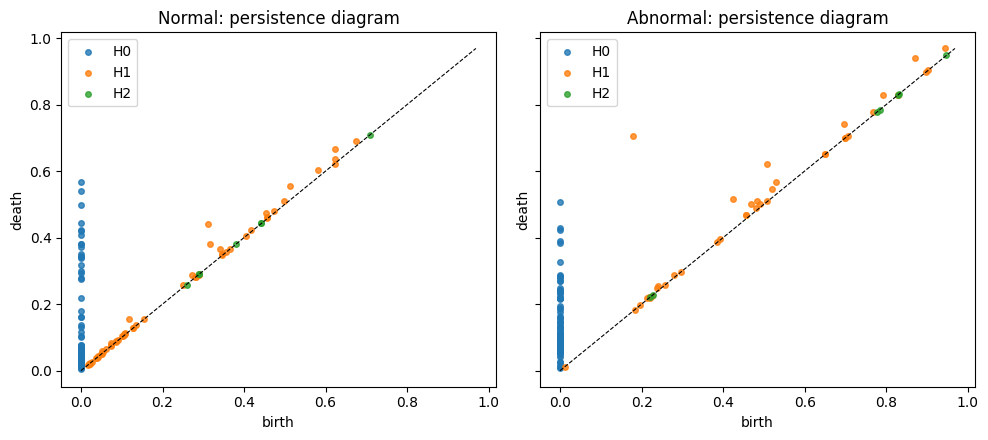

In [12]:
# (b) persistence diagrams (H0, H1, H2) for the same two beats
Ds = {n: DG['te'][i] for n, i in EX.items()}
lim = max(0.3, max(D[d].max() for D in Ds.values() for d in (0, 1, 2) if len(D[d])))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for a, (name, D) in zip(ax, Ds.items()):
    for d in (0, 1, 2):
        if len(D[d]): a.scatter(D[d][:,0], D[d][:,1], s=16, color=DCOL[d], label=DNAME[d], alpha=.8)
    a.plot([0, lim], [0, lim], 'k--', lw=.8); a.set_title(f'{name}: persistence diagram'); a.set_xlabel('birth'); a.set_ylabel('death'); a.legend()
plt.tight_layout(); plt.show()

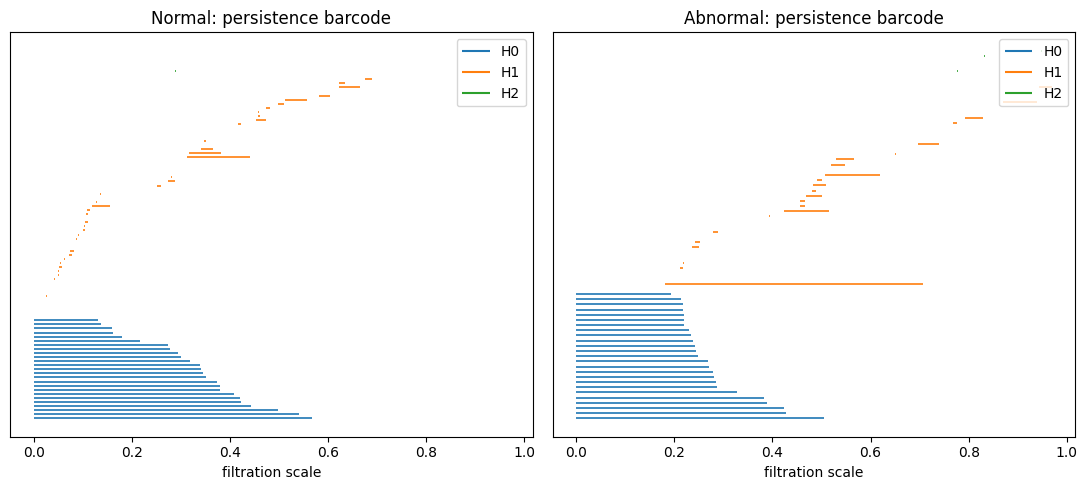

In [13]:
# (c) persistence barcodes (H0 limited to its 25 longest bars so the plot stays readable)
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
for a, (name, D) in zip(ax, Ds.items()):
    y = 0
    for d in (0, 1, 2):
        iv = D[d]
        if len(iv) == 0: continue
        iv = iv[np.argsort(-(iv[:,1] - iv[:,0]))][:25] if d == 0 else iv[np.argsort(iv[:,0])]
        for b_, d_ in iv: a.hlines(y, b_, d_, color=DCOL[d], lw=1.2); y += 1
    for d in (0, 1, 2): a.hlines([], 0, 0, color=DCOL[d], label=DNAME[d])
    a.set_title(f'{name}: persistence barcode'); a.set_xlabel('filtration scale'); a.set_yticks([]); a.legend()
plt.tight_layout(); plt.show()

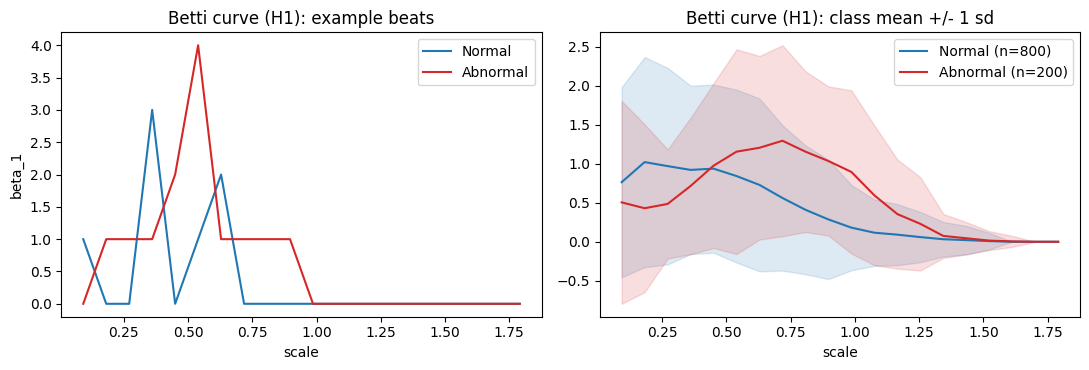

In [14]:
# (d) Betti curves (H1): two example beats and class averages over the test set
bc_te, ls_te, pi_te = TOPO['Betti curve (H1)']['te'], TOPO['landscape (H1)']['te'], TOPO['persistence image (H1)']['te']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, i in EX.items(): ax[0].plot(BC.grid_, bc_te[i], color=EXCOL[name], label=name)
ax[0].set_title('Betti curve (H1): example beats'); ax[0].set_xlabel('scale'); ax[0].set_ylabel('beta_1'); ax[0].legend()
for lab, name in [(0, 'Normal'), (1, 'Abnormal')]:
    M = bc_te[yte == lab]; ax[1].plot(BC.grid_, M.mean(0), color=EXCOL[name], label=f'{name} (n={len(M)})')
    ax[1].fill_between(BC.grid_, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color=EXCOL[name], alpha=.15)
ax[1].set_title('Betti curve (H1): class mean +/- 1 sd'); ax[1].set_xlabel('scale'); ax[1].legend()
plt.tight_layout(); plt.show()

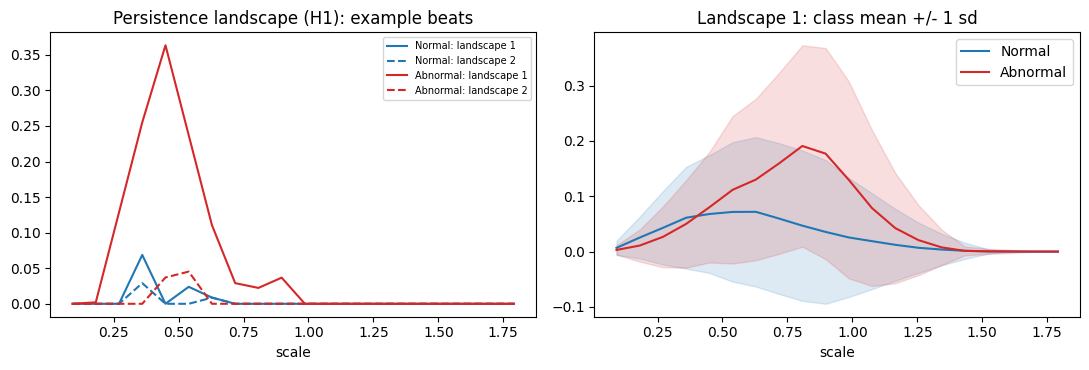

In [15]:
# (e) persistence landscapes (first two landscapes): examples and class means
L = ls_te.reshape(len(ls_te), 2, -1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, i in EX.items():
    ax[0].plot(LS.grid_, L[i, 0], color=EXCOL[name], label=f'{name}: landscape 1'); ax[0].plot(LS.grid_, L[i, 1], '--', color=EXCOL[name], label=f'{name}: landscape 2')
ax[0].set_title('Persistence landscape (H1): example beats'); ax[0].set_xlabel('scale'); ax[0].legend(fontsize=7)
for lab, name in [(0, 'Normal'), (1, 'Abnormal')]:
    M = L[yte == lab, 0]; ax[1].plot(LS.grid_, M.mean(0), color=EXCOL[name], label=name)
    ax[1].fill_between(LS.grid_, M.mean(0) - M.std(0), M.mean(0) + M.std(0), color=EXCOL[name], alpha=.15)
ax[1].set_title('Landscape 1: class mean +/- 1 sd'); ax[1].set_xlabel('scale'); ax[1].legend()
plt.tight_layout(); plt.show()

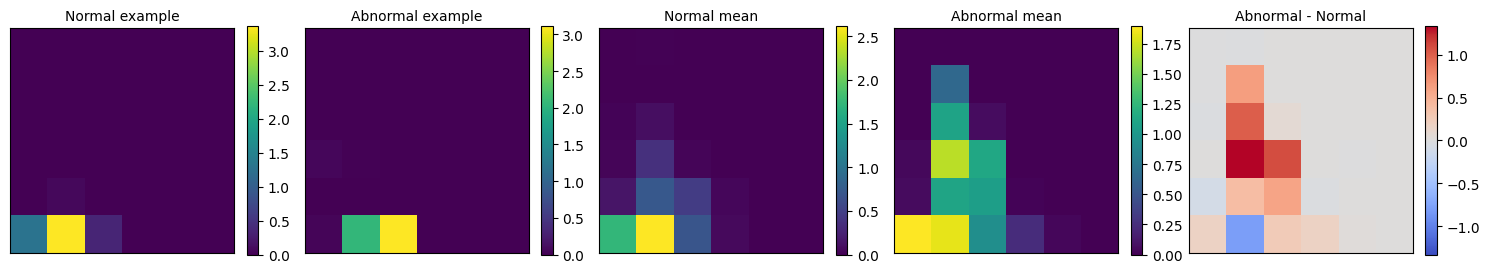

In [16]:
# (f) persistence images (H1, 6x6 grid; x = birth, y = persistence): examples, class means and their difference
img = lambda v: np.flip(v.reshape(6, 6), 0)
mean_n, mean_a = pi_te[yte == 0].mean(0), pi_te[yte == 1].mean(0)
panels = [('Normal example', img(pi_te[EX['Normal']])), ('Abnormal example', img(pi_te[EX['Abnormal']])),
          ('Normal mean', img(mean_n)), ('Abnormal mean', img(mean_a)), ('Abnormal - Normal', img(mean_a - mean_n))]
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for a, (t, im) in zip(ax, panels):
    kw = dict(cmap='coolwarm', vmin=-np.abs(im).max(), vmax=np.abs(im).max()) if 'Abnormal -' in t else dict(cmap='viridis')   # difference map centred on 0
    h = a.imshow(im, **kw); a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([]); plt.colorbar(h, ax=a, fraction=.046)
plt.tight_layout(); plt.show()

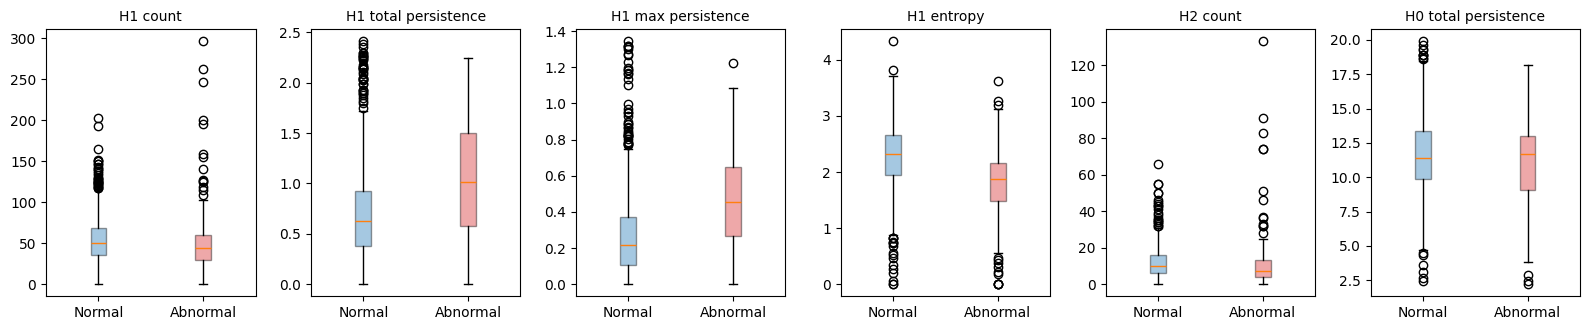

In [17]:
# (g) persistence statistics and entropy: normal vs abnormal test beats
names = [f'{d} {s}' for d in ('H0', 'H1', 'H2') for s in ('count', 'total persistence', 'max persistence', 'mean persistence', 'entropy')] + ['H1 longest loop', 'H1 2nd loop']
ST = pd.DataFrame(TOPO['persistence stats + entropy']['te'], columns=names)
show = ['H1 count', 'H1 total persistence', 'H1 max persistence', 'H1 entropy', 'H2 count', 'H0 total persistence']
fig, ax = plt.subplots(1, len(show), figsize=(16, 3.4))
for a, c in zip(ax, show):
    bp = a.boxplot([ST[c][yte == 0], ST[c][yte == 1]], labels=['Normal', 'Abnormal'], patch_artist=True)
    for p, col in zip(bp['boxes'], ['tab:blue', 'tab:red']): p.set_facecolor(col); p.set_alpha(.4)
    a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

## 5. Anomaly detection
Both detectors are trained on **normal beats only**. The alarm threshold is the 95th percentile of scores on held-out normal validation beats (about 5% false alarms by design). Three conditions, as in the breast cancer study: conventional, topological, combined.

In [18]:
SCORES = {}
def run(name, D):
    sc = StandardScaler().fit(D['tr'])
    A, V, Z = sc.transform(D['tr']), sc.transform(D['val']), sc.transform(D['te'])
    dets = {'IsolationForest': IsolationForest(n_estimators=300, random_state=SEED).fit(A),
            'OneClassSVM': OneClassSVM(nu=0.05, gamma='scale').fit(A)}
    rows = []
    for m, det in dets.items():
        score = lambda M: -det.decision_function(M)             # higher = more anomalous
        thr = np.percentile(score(V), 95); s = score(Z); pred = (s >= thr).astype(int); SCORES[(name, m)] = s
        rows.append([name, m, roc_auc_score(yte, s), average_precision_score(yte, s),
                     precision_score(yte, pred), recall_score(yte, pred), f1_score(yte, pred)])
    return rows
cols = ['features','model','ROC_AUC','PR_AUC','precision','recall','F1']
topo_all = {k: np.hstack([TOPO[n][k] for n in TOPO]) for k in CONV}
FS = {'conventional': CONV, 'topological': topo_all, 'combined': {k: np.hstack([CONV[k], topo_all[k]]) for k in CONV}}
res = pd.DataFrame(sum([run(n, D) for n, D in FS.items()], []), columns=cols).round(3)
print('Data:', SOURCE); print('Chance level for PR-AUC = anomaly share =', yte.mean()); res

Data: MIT-BIH (Kaggle pre-segmented beats)
Chance level for PR-AUC = anomaly share = 0.2


,features,model,ROC_AUC,PR_AUC,precision,recall,F1
0,conventional,IsolationForest,0.732,0.417,0.594,0.285,0.385
1,conventional,OneClassSVM,0.685,0.549,0.755,0.400,0.523
2,topological,IsolationForest,0.775,0.450,0.564,0.330,0.416
3,topological,OneClassSVM,0.734,0.463,0.630,0.255,0.363
4,combined,IsolationForest,0.783,0.470,0.622,0.345,0.444
5,combined,OneClassSVM,0.729,0.490,0.670,0.305,0.419


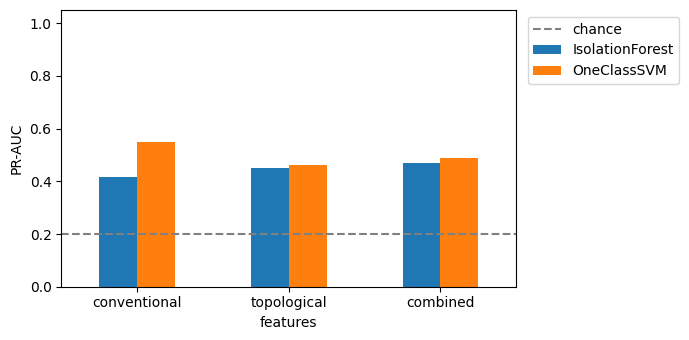

In [19]:
ax = res.pivot(index='features', columns='model', values='PR_AUC').loc[['conventional','topological','combined']].plot.bar(rot=0, figsize=(7,3.5))
ax.axhline(yte.mean(), color='gray', ls='--', label='chance'); ax.set_ylabel('PR-AUC'); ax.set_ylim(0, 1.05); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

### Evaluation pictures: ROC and precision-recall curves, score distributions

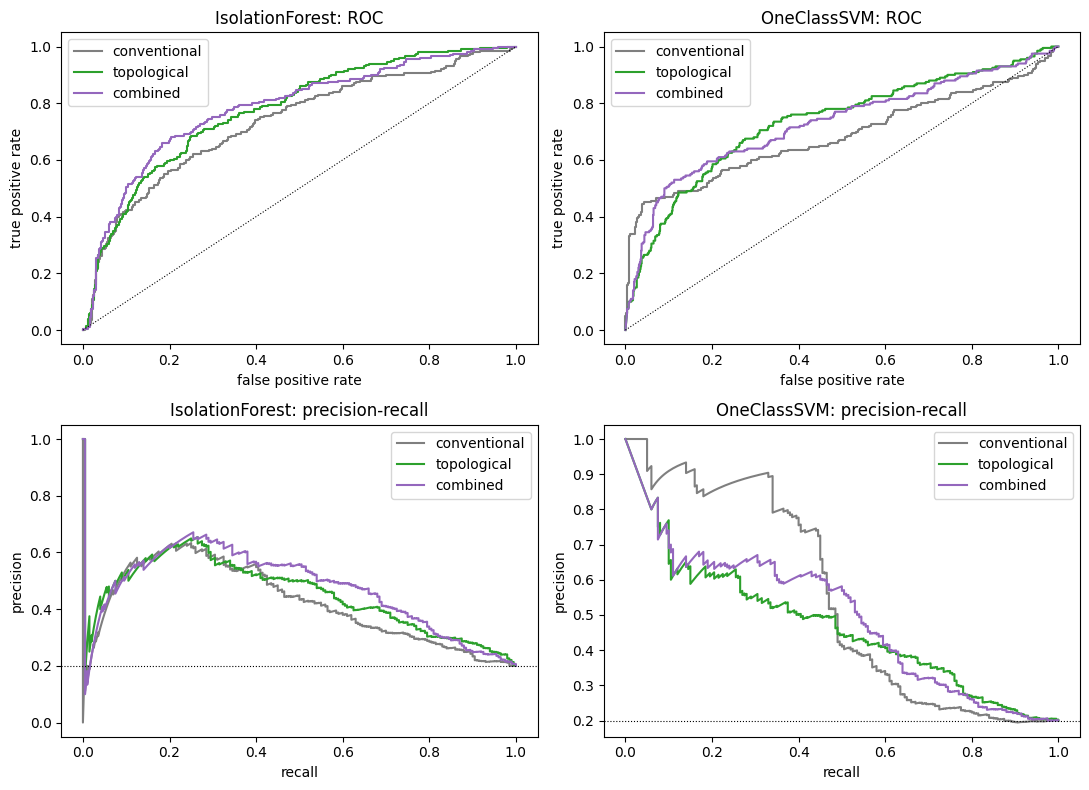

In [20]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for j, m in enumerate(['IsolationForest', 'OneClassSVM']):
    for n, col in zip(['conventional', 'topological', 'combined'], ['tab:gray', 'tab:green', 'tab:purple']):
        s = SCORES[(n, m)]; fpr, tpr, _ = roc_curve(yte, s); p, r, _ = precision_recall_curve(yte, s)
        ax[0, j].plot(fpr, tpr, color=col, label=n); ax[1, j].plot(r, p, color=col, label=n)
    ax[0, j].plot([0, 1], [0, 1], 'k:', lw=.8); ax[0, j].set_title(f'{m}: ROC'); ax[0, j].set_xlabel('false positive rate'); ax[0, j].set_ylabel('true positive rate'); ax[0, j].legend()
    ax[1, j].axhline(yte.mean(), color='k', ls=':', lw=.8); ax[1, j].set_title(f'{m}: precision-recall'); ax[1, j].set_xlabel('recall'); ax[1, j].set_ylabel('precision'); ax[1, j].legend()
plt.tight_layout(); plt.show()

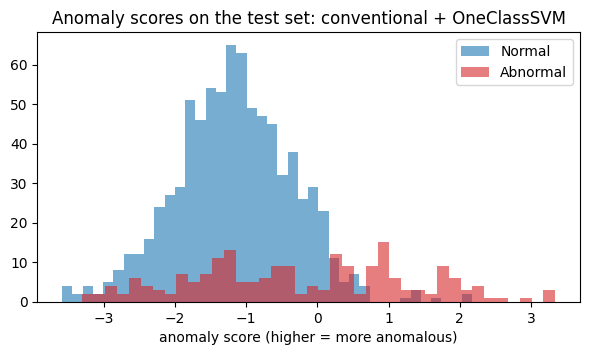

In [21]:
best = res.sort_values('PR_AUC', ascending=False).iloc[0]; key = (best.features, best.model); s = SCORES[key]
plt.figure(figsize=(7, 3.5)); plt.hist(s[yte == 0], bins=40, alpha=.6, label='Normal', color='tab:blue'); plt.hist(s[yte == 1], bins=40, alpha=.6, label='Abnormal', color='tab:red')
plt.title(f'Anomaly scores on the test set: {key[0]} + {key[1]}'); plt.xlabel('anomaly score (higher = more anomalous)'); plt.legend(); plt.show()

### Which topological representation helps? (each used alone)

In [22]:
abl = pd.DataFrame(sum([run(n, D) for n, D in TOPO.items()], []), columns=cols).round(3).rename(columns={'features':'topological representation'})
abl.sort_values('PR_AUC', ascending=False)

,topological representation,model,ROC_AUC,PR_AUC,precision,recall,F1
1,persistence stats + entropy,OneClassSVM,0.743,0.554,0.708,0.375,0.490
6,persistence image (H1),IsolationForest,0.721,0.434,0.562,0.180,0.273
5,landscape (H1),OneClassSVM,0.722,0.414,0.562,0.205,0.300
7,persistence image (H1),OneClassSVM,0.657,0.414,0.554,0.180,0.272
2,Betti curve (H1),IsolationForest,0.725,0.408,0.533,0.245,0.336
0,persistence stats + entropy,IsolationForest,0.765,0.403,0.466,0.205,0.285
4,landscape (H1),IsolationForest,0.690,0.397,0.562,0.295,0.387
3,Betti curve (H1),OneClassSVM,0.602,0.321,0.448,0.130,0.202
